# Detector de sesgo de género · análisis de una biografía

Analiza **un texto** (una biografía al azar del dataset o la que tú escribas) con las variables y agrupaciones
finales del estudio y lo compara con las biografías anotadas en la parte 2:

1. **Dibujo de flechas** del texto: a la **izquierda, en azul**, las dimensiones agénticas (lo que se suele destacar
   más en hombres: agencia y estatus, perfil técnico y empresarial); a la **derecha, en rojo**, las dimensiones de sesgo
   (marcado de género, vida personal, calidez y emoción, temas comunales añadidos, agencia diluida). Las marcas grises
   indican la media de hombres y de mujeres de referencia.
2. **Métrica de sesgo** (0 = ningún sesgo, 1 = todos): total, sesgo por presencia y omisión agéntica, comparada con
   la **referencia sin sesgo** (cómo se describe a los hombres) y con **lo habitual en biografías de mujeres**.
3. **Tablas con los datos**: cada dimensión (rasgos detectados, % en el texto y en la referencia) y cada rasgo estudiado
   (detectado / no detectado / no aplica, si entra en la métrica, cuánto aporta y su frecuencia en hombres y mujeres),
   con la frase del texto donde aparece. Las frases también se resaltan en el texto.

**Profesión.** Si la profesión es una de las 28 del estudio, se compara **con su profesión y con todas juntas**. Si no
está, solo con todas juntas. Si no se indica, el modelo la deduce del texto.

**Requisitos:** va en la misma carpeta que las partes 1 y 2 y usa sus resultados (`anotaciones_ampliacion.csv`,
`anotaciones_confirmacion.csv`, `cache/` y `resultados/confirmatorio_ampliacion.csv`). Cada texto hace unas 5 llamadas
al modelo.

**Uso:** ejecuta las secciones 1 a 6 una vez. Después, la 7 (biografía al azar) o la 8 (tu texto) tantas veces como quieras.

## 1. Configuración

In [13]:
import os, re, json, time, warnings, html
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

CACHE, RESULTADOS = Path("cache"), Path("resultados")
ENV = "/workspace/equipo10/.env"
MODELO = "Qwen3.5-397B-A17B"

FASE = "ampliacion"                       # las variables confirmadas salen de la ampliación (FDR 0,10)
REFERENCIA = ["ampliacion", "confirmacion"]   # biografías anotadas que se usan como referencia (las dos muestras nuevas)
VARIABLES_METRICA = "confirmadas"
PESO_PRESENCIA, PESO_OMISION = 0.70, 0.30
MIN_TASA_HOMBRES = 10
K_SUAVIZADO = 40

PROFESIONES = ["accountant", "architect", "attorney", "chiropractor", "comedian", "composer",
               "dentist", "dietitian", "dj", "filmmaker", "interior_designer", "journalist",
               "model", "nurse", "painter", "paralegal", "pastor", "personal_trainer",
               "photographer", "physician", "poet", "professor", "psychologist", "rapper",
               "software_engineer", "surgeon", "teacher", "yoga_teacher"]
NOMBRES = {
    "accountant": "contable", "architect": "arquitecto/a", "attorney": "abogado/a",
    "chiropractor": "quiropráctico/a", "comedian": "cómico/a", "composer": "compositor/a",
    "dentist": "dentista", "dietitian": "dietista", "dj": "DJ", "filmmaker": "cineasta",
    "interior_designer": "interiorista", "journalist": "periodista", "model": "modelo",
    "nurse": "enfermero/a", "painter": "pintor/a", "paralegal": "asistente legal", "pastor": "pastor/a",
    "personal_trainer": "entrenador/a personal", "photographer": "fotógrafo/a", "physician": "médico/a",
    "poet": "poeta", "professor": "profesor/a universitario/a", "psychologist": "psicólogo/a",
    "rapper": "rapero/a", "software_engineer": "ingeniero/a de software", "surgeon": "cirujano/a",
    "teacher": "docente (escuela)", "yoga_teacher": "profesor/a de yoga",
}
AZUL, ROJO = "#2a78d6", "#eb6834"
TINTA, TINTA_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
print("Configuración cargada.")

Configuración cargada.


## 2. Conexión con el modelo
La dirección y el token se leen del archivo `.env`.

In [14]:
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(ENV, override=True)
#
ai_endpoint_url = os.getenv("OVH_AI_ENDPOINTS_URL")
ai_endpoint_token = os.getenv("OVH_AI_ENDPOINTS_ACCESS_TOKEN")
if not ai_endpoint_url or not ai_endpoint_token:
    raise RuntimeError(f"No se han podido leer la dirección o el token del archivo {ENV}.")
client = OpenAI(base_url=ai_endpoint_url, api_key=ai_endpoint_token)
#
def preguntar(prompt):
    for intento in range(3):
        try:
            r = client.chat.completions.create(model=MODELO, messages=[{"role": "user", "content": prompt}],
                                               temperature=0, reasoning_effort="none")
            contenido = r.choices[0].message.content
            ini, fin = contenido.find("{"), contenido.rfind("}")
            return json.loads(contenido[ini:fin + 1]) if ini != -1 else {}
        except json.JSONDecodeError:
            return {}
        except Exception as e:
            print("Error de conexión, reintentando:", type(e).__name__)
            time.sleep(3 * (intento + 1))
    return {}

def hay_conexion():
    return preguntar('Return the JSON {"ok": true}').get("ok") is True

print("Conexión con el modelo:", "OK" if hay_conexion() else "FALLA (no lances la anotación)")

Conexión con el modelo: OK


## 3. Enmascarado y variables
Las mismas funciones y preguntas que la parte 2, para que el texto sea comparable con la referencia.

In [15]:
PRONOMBRES = r"\b(she|he|her|hers|him|his|herself|himself|mrs|mr|ms|miss|mister|madam)\b"
_nlp = None

def get_nlp():
    global _nlp
    if _nlp is None:
        import spacy
        _nlp = spacy.load("en_core_web_sm", disable=["tagger", "parser", "attribute_ruler", "lemmatizer"])
    return _nlp

def enmascarar_lote(textos):
    salida = []
    for doc in get_nlp().pipe(textos, batch_size=500):
        t = doc.text
        for ent in reversed(doc.ents):
            if ent.label_ == "PERSON":
                t = t[:ent.start_char] + "[NAME]" + t[ent.end_char:]
        salida.append(re.sub(PRONOMBRES, "[X]", t, flags=re.IGNORECASE))
    return salida

print("Enmascarado listo.")

Enmascarado listo.


In [16]:
VARIABLES_FORMA = {
    # --- Control ---
    "tipo_texto": (["biografia", "no_biografia"],
        "Is this text a description of a person's work, career, education, skills or life? Answer 'biografia' if it is, even if it starts mid-story, is short, lists services or specialties, or contains some extra details. Answer 'no_biografia' ONLY if it gives almost no information about the person (just contact details, navigation text, an advertisement or an unrelated text)."),
    # --- Vida personal ---
    "menciona_pareja": ("bool",
        "Does the text mention a spouse or romantic partner (husband, wife, partner, fiancé/fiancée, boyfriend, girlfriend, significant other)?"),
    "papel_pareja": (["coprotagonista", "apoyo", "solo_mencion", "no_aparece"],
        "If a spouse or partner is mentioned, what role do they play? 'coprotagonista' if the partner shares the person's professional work or achievements ('she and her husband founded', 'works in conjunction with her husband'); 'apoyo' if the partner is described as supporting the person ('supported in ministry by his wife'); 'solo_mencion' if the partner is only mentioned as a personal detail ('lives with his wife and two children'); 'no_aparece' if no partner is mentioned."),
    "menciona_hijos": ("bool",
        "Does the text mention children or grandchildren (sons, daughters, kids, stepchildren, 'mother of', 'father of', 'mom', 'dad', 'parent of')?"),
    "menciona_estado_civil": ("bool",
        "Does the text mention marital status (married, single, divorced, widowed, engaged)?"),
    "menciona_padres_origen": ("bool",
        "Does the text mention the person's parents, siblings or family background, or where they grew up or were raised (hometown, childhood, family origins)?"),
    "presentada_por_otra_persona": ("bool",
        "Is the person introduced or defined mainly through their relationship with a partner or family member, so that this relationship is presented as a central part of who they are ('wife of', 'former wife of actor…', 'daughter of famous…', 'married to NBA player…')? Do NOT count: describing who they work for or assist as part of their job (e.g. a paralegal assisting an attorney), being discovered or helped by someone, simply mentioning family background, or simply saying they are married."),
    "menciona_aficiones": ("bool",
        "Does the text mention hobbies, free time or personal interests outside work (sports, travel, cooking, reading, music, pets, 'in their spare time', 'when not at work')?"),
    "posicion_mencion_familiar": (["primera_mitad", "segunda_mitad", "no_aparece"],
        "Where does the FIRST mention of family (partner, children, parents, marital status) appear in the text?"),
    # --- Logros, formación y trayectoria ---
    "n_logros": ("int",
        "How many distinct achievements or recognitions are mentioned (awards, prizes, honours, rankings, nominations, grants, being selected or named for something, notable publications, exhibitions, record sales, notable clients)? Do not count degrees or certifications."),
    "n_credenciales": ("int",
        "How many distinct educational or professional credentials are mentioned (degrees, diplomas, certifications, licenses, board certifications, fellowships, residencies, training programs)?"),
    "menciona_experiencia": ("bool",
        "Does the text mention length of experience or career ('over 10 years of experience', 'two decades', 'since 1995', 'veteran', 'seasoned', 'long career')?"),
    "menciona_liderazgo": ("bool",
        "Is the person described in a leadership, management or ownership role (founder, co-founder, owner, director, head, chief, CEO, president, chair, manager, partner in a firm, principal, leads or supervises a team or department)?"),
    "atribuye_logros_a_otros": (["si", "no", "sin_logros"],
        "Are any of the person's achievements credited to other people or to circumstances (a mentor, spouse, family, team, collaborators, luck, being discovered by someone, support from others)? Answer 'sin_logros' if no achievements are mentioned."),
    "logros_en_pasiva": (["si", "no", "sin_logros"],
        "Is any achievement described in the passive voice ('was awarded', 'was named', 'was selected', 'was recognized', 'was honored')? Answer 'sin_logros' if no achievements are mentioned."),
    # --- Orientación profesional ---
    "orientacion_cuidado": ("bool",
        "Does the text emphasize helping, caring for or serving others (patients, clients, students, families, community), e.g. 'dedicated to helping', 'committed to patient care', 'passion for serving'?"),
    "menciona_impacto": ("bool",
        "Does the text emphasize the person's influence, impact, reach or authority (shaped the field, widely cited, recognized authority, transformed, led change, international reputation)?"),
    "menciona_innovacion": ("bool",
        "Does the text describe the person as creating, inventing or innovating (developed a new method, patents, founded, pioneered a technique, built a product)?"),
    "menciona_docencia_mentoria": ("bool",
        "Does the text mention teaching, mentoring, training or supervising others' learning?"),
    "menciona_voluntariado": ("bool",
        "Does the text mention volunteering, charity, non-profit work, community service or pro bono work?"),
    "menciona_especializacion": ("bool",
        "Does the text mention a specific area of specialization or technical expertise (specializes in, focuses on, expert in a specific technique or area)?"),
    # --- Excepcionalidad y marcado de género (marcado_genero, pregunta corregida) ---
    "excepcionalidad": ("bool",
        "Is the person described as exceptional or a pioneer within a group or field: first, only, one of the few, pioneer, pioneering, trailblazer, groundbreaking figure, breaking barriers, rare, unique among peers, leading the way? It must describe the person, not a product or place (e.g. 'the first clinic in town' does not count)."),
    "marcado_genero": ("bool",
        "Does the text explicitly mark the person's gender in relation to their profession or role: 'female engineer', 'woman surgeon', 'male nurse', 'lady doctor', 'women in tech', 'first woman to…'? Do NOT count gendered job titles on their own (actress, actor, chairwoman, chairman, spokeswoman, spokesman, businesswoman, waitress): they are a separate question."),
    "marca_genero_persona": ("bool",
        "Does the text explicitly point out the person's own gender as relevant to who they are or what they do ('as a woman', 'as a Black Muslim woman', 'female engineer', 'male nurse', 'Best Female Comic', 'first woman to…', 'everywoman', 'ChiroMom')? Do NOT count gendered job titles alone (actress, spokeswoman) or mentions of women-only or men-only groups."),
    "titulo_con_genero": ("bool",
        "Does the text use a gendered job title or role noun for the person (actress, actor, chairwoman, chairman, spokeswoman, spokesman, businesswoman, businessman, songstress, hostess, waitress)?"),
    "espacio_un_genero": ("bool",
        "Does the text mention groups, events, awards, shows or organizations restricted to or focused on one gender ('all-female showcase', 'women's network', 'Women in Law', 'men's ministry', 'ladies' night')?"),
    # --- Lenguaje ---
    "n_adj_agencia": ("int",
        "How many words describe agency or competence (confident, ambitious, driven, independent, decisive, assertive, determined, accomplished, successful, influential, expert, outstanding, leading)?"),
    "n_adj_calidez": ("int",
        "How many words describe warmth or communal traits (warm, caring, compassionate, kind, supportive, nurturing, helpful, friendly, patient, gentle, empathetic, approachable, loving)?"),
    "n_palabras_capacidad": ("int",
        "How many words attribute success to ability or talent (talented, gifted, brilliant, intelligent, skilled, natural, exceptional, genius, innovative, creative)?"),
    "n_palabras_esfuerzo": ("int",
        "How many words attribute success to effort (hardworking, dedicated, diligent, committed, tireless, conscientious, meticulous, persistent, devoted, works hard)?"),
    "n_expresiones_duda": ("int",
        "How many expressions cast doubt or give faint praise (tries to, hopes to, aspiring, may, seems, somewhat, fairly, adequate, although, despite, still learning)?"),
    "n_terminos_emocion": ("int",
        "How many words refer to emotions or temperament (passionate, loves, enjoys, excited, proud, happy, enthusiastic, sensitive, emotional, cheerful, calm, energetic)?"),
    "n_verbos_rol_activo": ("int",
        "How many verbs present the person as the main agent who leads, decides or creates (leads, directs, manages, founded, created, developed, designed, built, launched, oversees, heads)?"),
    "n_verbos_rol_apoyo": ("int",
        "How many verbs present the person in a supporting or assisting role (assists, supports, helps, aids, contributes to, works with, works under, collaborates on, serves)?"),
    "tono": (["positivo", "neutro", "negativo"],
        "What is the overall tone of the text?"),
}

VARIABLES_CONTEXTO = {
    # --- Encuadre: el sesgo es 'encuadre' (se añade o se etiqueta sin un hecho concreto) ---
    "menciona_apariencia_ctx": (["no_aparece", "relevante", "no_relevante"],
        "Does the text comment on the person's own physical appearance (looks, beauty, attractiveness, body, height, weight, hair, clothing, style)? Answer 'no_aparece' if not. Answer 'relevante' if the person's work is directly about their image or appearance (model, actor or actress, fitness or beauty influencer, stylist, TV presenter) and the comment relates to that work. Answer 'no_relevante' if their appearance is mentioned although it has nothing to do with their work. Judge only from the text itself, whatever the profession."),
    "bienestar_sanacion_ctx": (["no_aparece", "hecho", "encuadre"],
        "Does the text mention wellness, healing or holistic well-being (healing, wellness, holistic, mindfulness, self-care, emotional well-being, nurturing)? Answer 'no_aparece' if it is not mentioned. Answer 'hecho' if it describes something concrete the person does: it is their field, specialty, clients, products or services, or a specific activity, organization or project. Answer 'encuadre' if it appears as a label, adjective or way of presenting the person or their work, without a concrete fact behind it or without being needed to describe what they do (for example: a lawyer 'who brings a holistic, healing touch to every case', an accountant who 'radiates calm and well-being'). Judge only from the text itself, whatever the profession. Do not count comments on the person's own appearance or own family."),
    "infancia_familias_ctx": (["no_aparece", "hecho", "encuadre"],
        "Does the text mention children, babies, parents or families as people the person works with or for (pediatric, early childhood, maternity, parenting, family services)? Answer 'no_aparece' if it is not mentioned. Answer 'hecho' if it describes something concrete the person does: it is their field, specialty, clients, products or services, or a specific activity, organization or project. Answer 'encuadre' if it appears as a label, adjective or way of presenting the person or their work, without a concrete fact behind it or without being needed to describe what they do (for example: a general dentist described as 'great with kids', a lawyer who 'also enjoys helping families', a 'family-friendly' practice). Judge only from the text itself, whatever the profession. Do not count comments on the person's own appearance or own family."),
    "estetica_belleza_ctx": (["no_aparece", "hecho", "encuadre"],
        "Does the text mention beauty, fashion, style, makeup, hair, flowers or decoration as a topic? Answer 'no_aparece' if it is not mentioned. Answer 'hecho' if it describes something concrete the person does: it is their field, specialty, clients, products or services, or a specific activity, organization or project. Answer 'encuadre' if it appears as a label, adjective or way of presenting the person or their work, without a concrete fact behind it or without being needed to describe what they do (for example: a lawyer 'with a passion for fashion', an engineer 'known for her sense of style', a dentist who 'loves makeup and interior decor'). Judge only from the text itself, whatever the profession. Do not count comments on the person's own appearance or own family."),
    "activismo_justicia_social_ctx": (["no_aparece", "hecho", "encuadre"],
        "Does the text mention activism or social causes (feminism, women's rights, gender equality, empowerment, civil or human rights, giving a voice to marginalized people)? Answer 'no_aparece' if not. Answer 'hecho' if it describes something concrete the person does: their job is in this field, or they founded, lead, work for or volunteer at a specific organization, campaign, case or project. Answer 'encuadre' if these words are used to label or frame the person or their ordinary work without a concrete activity behind them (for example: 'empowering women through yoga', 'a feminist voice in comedy', 'inspiring girls to dream big')."),
    # --- Puesta en valor: el sesgo es 'aplica_no_destaca' (forma parte de su trabajo y no se valora) ---
    "ciencia_cuantitativa_ctx": (["no_aplica", "aplica_no_destaca", "aplica_destaca"],
        "Is the person's work related to hard or quantitative sciences (physics, mathematics, statistics, economics, data analysis, laboratory or experimental research, engineering calculations, quantitative finance)? Answer 'no_aplica' if their work has nothing to do with it. If it does, answer 'aplica_destaca' if the text highlights or values that side of their work (methods, data, models, research, lab work, technical or scientific expertise), or 'aplica_no_destaca' if the text describes their work without mentioning or valuing that side."),
    "tecnologia_sistemas_ctx": (["no_aplica", "aplica_no_destaca", "aplica_destaca"],
        "Is the person's work related to technology, computers or technical systems (software, hardware, engineering, digital tools, technical equipment)? Answer 'no_aplica' if their work has nothing to do with it. If it does, answer 'aplica_destaca' if the text highlights or values that side of their work (technical skills, tools, systems built or managed, programming, technical expertise), or 'aplica_no_destaca' if the text describes their work without mentioning or valuing that side."),
    "empresa_negocio_ctx": (["no_aplica", "aplica_no_destaca", "aplica_destaca"],
        "Does the person own, found, run or co-run a business, company, firm, studio or private practice? Answer 'no_aplica' if the text gives no sign of that. If they do, answer 'aplica_destaca' if the text values that business (its growth, success, size, clients, achievements, reputation, or the person's role in building it), or 'aplica_no_destaca' if it is only mentioned plainly ('owns a bakery', 'has a private practice') without valuing it."),
    # --- Variables descubiertas que se mantienen (sí / no) ---
    "pasion_emocion": ("bool",
        "Does the text describe the person's work or motivation in emotional terms: passion, love, enjoyment, inspiration, dreams or feelings (passionate about, loves, enjoys, is inspired by, dreams of, heartfelt, joyful, finds fulfilment, deeply moved, emotional)? Count it even if other words are used."),
    "fama_prestigio": ("bool",
        "Does the text emphasize the person's fame, prestige or authority (famous, renowned, world-renowned, leading expert, highly regarded, recognized authority, prominent, acclaimed, legendary, reaches thousands or millions of people, medals)? Count it even if other words are used."),
    "valentia_audacia": ("bool",
        "Is the person described as brave, bold or tough (brave, courageous, fearless, bold, daring, audacious, intrepid, tough, gritty, unafraid, takes risks)? Count it even if other words are used."),
    "aficiones_hogar_creativas": ("bool",
        "Does the text mention home, craft, animal or creative leisure activities as hobbies or personal interests (dogs, cats or other pets, animals, knitting, sewing, crafts, gardening, baking, cooking, flowers, dancing)?"),
}

VARIABLES_NOMBRE = {
    "forma_nombrar": (["nombre_pila", "apellido", "nombre_completo", "solo_pronombres"],
        "How is the person mainly referred to in the text: by first name only ('nombre_pila'), by surname only, with or without a title like 'Dr. Smith' ('apellido'), by full name ('nombre_completo'), or only with pronouns, with no name at all ('solo_pronombres')?"),
    "usa_titulo_ctx": (["no_aplica", "aplica_no_usa", "aplica_usa"],
        "Does the text show that the person holds a title normally used to address them (a doctorate or PhD; a medical, dental or chiropractic degree such as MD, DO, DDS, DMD, DC; or a professorship)? Answer 'no_aplica' if the text gives no sign of such a title. If it does, answer 'aplica_usa' if the text refers to the person with the title at least once ('Dr. Smith', 'Professor Smith', 'Jane Smith, PhD'), or 'aplica_no_usa' if it never uses the title to refer to them."),
}

TIPOS = {k: t for k, (t, _) in {**VARIABLES_FORMA, **VARIABLES_CONTEXTO, **VARIABLES_NOMBRE}.items()}

def formato(tipo):
    if tipo == "bool":
        return "true or false"
    if tipo == "int":
        return "an integer, 0 if none"
    return "one of " + ", ".join(f'"{o}"' for o in tipo)

def construir_prompt(texto, variables):
    preguntas = "\n".join(f'- "{k}" ({formato(t)}): {p}' for k, (t, p) in variables.items())
    return ("You are annotating professional biographies for a research study on language.\n"
            "Some words were replaced with [X] (pronouns) or [NAME] (person names). "
            "Do not try to guess the person's gender.\n"
            "Answer every question about the biography below. When a question lists example words, count the idea "
            "even if the text expresses it with different words or synonyms.\n"
            "Return ONLY a JSON object with exactly these keys:\n"
            f"{preguntas}\n\nBiography:\n\"\"\"{texto}\"\"\"")

def limpiar(respuesta, variables):
    fila = {}
    for nombre, (tipo, _) in variables.items():
        v = respuesta.get(nombre)
        if tipo == "bool":
            fila[nombre] = v if isinstance(v, bool) else None
        elif tipo == "int":
            ok = isinstance(v, (int, float)) and not isinstance(v, bool) and v >= 0
            fila[nombre] = int(v) if ok else None
        else:
            fila[nombre] = v if v in tipo else None
    return fila

def anotar(texto, texto_enmascarado):
    fila = limpiar(preguntar(construir_prompt(texto_enmascarado, VARIABLES_FORMA)), VARIABLES_FORMA)
    fila.update(limpiar(preguntar(construir_prompt(texto_enmascarado, VARIABLES_CONTEXTO)), VARIABLES_CONTEXTO))
    fila.update(limpiar(preguntar(construir_prompt(texto, VARIABLES_NOMBRE)), VARIABLES_NOMBRE))
    fila["n_palabras"] = len(texto.split())
    return fila

print(len(VARIABLES_FORMA), "de forma +", len(VARIABLES_CONTEXTO), "de contexto +", len(VARIABLES_NOMBRE), "de nombre.")

35 de forma + 12 de contexto + 2 de nombre.


## 4. Variables de sesgo, dimensiones y codificación
Igual que en la parte 2 (agrupación final).

In [17]:
DIMENSIONES = {
    "M1": ("Marcado de género", "mujeres",
           ["marcado_genero", "marca_genero_persona", "forma_nombrar"]),
    "M2": ("Vida personal y aspecto", "mujeres",
           ["menciona_pareja", "menciona_hijos", "menciona_estado_civil", "menciona_padres_origen",
            "presentada_por_otra_persona", "menciona_aficiones", "menciona_apariencia_ctx"]),
    "M3": ("Calidez y emoción", "mujeres",
           ["orientacion_cuidado", "n_adj_calidez", "n_terminos_emocion", "pasion_emocion", "bienestar_sanacion_ctx"]),
    "M4": ("Temas comunales añadidos", "mujeres",
           ["infancia_familias_ctx", "estetica_belleza_ctx", "activismo_justicia_social_ctx",
            "aficiones_hogar_creativas", "menciona_voluntariado"]),
    "M5": ("Agencia y estatus", "hombres",
           ["n_adj_agencia", "n_logros", "menciona_liderazgo", "menciona_impacto", "menciona_innovacion",
            "fama_prestigio", "valentia_audacia", "n_verbos_rol_activo", "usa_titulo_ctx", "excepcionalidad"]),
    "M6": ("Perfil técnico y empresarial puesto en valor", "hombres",
           ["ciencia_cuantitativa_ctx", "tecnologia_sistemas_ctx", "empresa_negocio_ctx"]),
    "M7": ("Agencia diluida", "mujeres",
           ["atribuye_logros_a_otros", "logros_en_pasiva", "n_verbos_rol_apoyo", "n_expresiones_duda", "papel_pareja"]),
}
DIM_DE = {v: d for d, (_, _, vs) in DIMENSIONES.items() for v in vs}
LADO = {v: DIMENSIONES[d][1] for v, d in DIM_DE.items()}
VARIABLES_SESGO = list(DIM_DE)

ETIQUETA = {   # cómo se describe cada rasgo en las explicaciones
    "marcado_genero": "Se marca su género en relación con la profesión (female engineer, male nurse…)",
    "marca_genero_persona": "Se destaca su género como algo relevante (as a woman…)",
    "excepcionalidad": "Se la presenta como excepcional en su campo (first, only, one of the few…)",
    "forma_nombrar": "Se la nombra por el nombre de pila",
    "menciona_pareja": "Se menciona a su pareja",
    "menciona_hijos": "Se mencionan sus hijos",
    "menciona_estado_civil": "Se menciona su estado civil",
    "menciona_padres_origen": "Se mencionan sus padres u origen familiar",
    "presentada_por_otra_persona": "Se la presenta a través de su pareja o su familia",
    "menciona_aficiones": "Se mencionan aficiones personales",
    "menciona_apariencia_ctx": "Se comenta su aspecto físico sin relación con su trabajo",
    "orientacion_cuidado": "Se pone el foco en cuidar o ayudar a otros",
    "n_adj_calidez": "Adjetivos de calidez (warm, caring, supportive…)",
    "n_terminos_emocion": "Palabras de emoción (passionate, loves, enjoys…)",
    "pasion_emocion": "La motivación se cuenta como emoción o pasión",
    "bienestar_sanacion_ctx": "Bienestar o sanación como etiqueta, sin ser su trabajo",
    "infancia_familias_ctx": "Niños o familias como etiqueta, sin ser su especialidad",
    "estetica_belleza_ctx": "Belleza, moda o estilo como etiqueta, sin ser su sector",
    "activismo_justicia_social_ctx": "Palabras de activismo sin una actividad concreta detrás",
    "aficiones_hogar_creativas": "Aficiones del hogar, creativas o con animales",
    "menciona_voluntariado": "Se menciona voluntariado o labor benéfica",
    "n_adj_agencia": "Adjetivos de competencia (accomplished, expert, leading…)",
    "n_logros": "Logros o reconocimientos concretos",
    "menciona_liderazgo": "Su papel de liderazgo o dirección",
    "menciona_impacto": "Su impacto o influencia",
    "menciona_innovacion": "Lo que ha creado o innovado",
    "fama_prestigio": "Su prestigio o reconocimiento",
    "valentia_audacia": "Valentía o audacia",
    "n_verbos_rol_activo": "Verbos en los que lidera, decide o crea",
    "usa_titulo_ctx": "Se la nombra con su título (Dr., Prof., PhD)",
    "ciencia_cuantitativa_ctx": "Se destaca su perfil científico o cuantitativo",
    "tecnologia_sistemas_ctx": "Se destaca su perfil técnico o tecnológico",
    "empresa_negocio_ctx": "Se pone en valor su empresa o negocio",
    "atribuye_logros_a_otros": "Su mérito se atribuye a otras personas o a la suerte",
    "logros_en_pasiva": "Sus logros se cuentan en pasiva (was awarded…)",
    "n_verbos_rol_apoyo": "Verbos de apoyo (assists, supports, works under…)",
    "n_expresiones_duda": "Expresiones de duda o elogio tibio (tries to, hopes to…)",
    "papel_pareja": "Su mérito se comparte con la pareja",
}

# Valores que cuentan como 1 y como "no aplica" en las variables de opciones
UNO = {"menciona_apariencia_ctx": {"no_relevante"}, "forma_nombrar": {"nombre_pila"},
       "papel_pareja": {"coprotagonista", "apoyo"}, "atribuye_logros_a_otros": {"si"}, "logros_en_pasiva": {"si"},
       "usa_titulo_ctx": {"aplica_usa"}}
NO_APLICA = {"forma_nombrar": {"solo_pronombres"}, "papel_pareja": {"no_aparece"},
             "atribuye_logros_a_otros": {"sin_logros"}, "logros_en_pasiva": {"sin_logros"},
             "usa_titulo_ctx": {"no_aplica"}}
for v in ["bienestar_sanacion_ctx", "infancia_familias_ctx", "estetica_belleza_ctx", "activismo_justicia_social_ctx"]:
    UNO[v] = {"encuadre"}
for v in ["ciencia_cuantitativa_ctx", "tecnologia_sistemas_ctx", "empresa_negocio_ctx"]:
    UNO[v], NO_APLICA[v] = {"aplica_destaca"}, {"no_aplica"}

def codificar_valor(variable, x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    tipo = TIPOS[variable]
    if tipo == "bool":
        return 1.0 if str(x).strip().lower() in ("true", "1", "1.0") else 0.0
    if tipo == "int":
        return float(float(x) > 0)
    if x in NO_APLICA.get(variable, ()):
        return np.nan
    return float(x in UNO[variable])

def codificar(df):
    """Tabla 0 / 1 / vacío de las variables de sesgo."""
    return pd.DataFrame({v: df[v].map(lambda x: codificar_valor(v, x)) for v in VARIABLES_SESGO if v in df.columns},
                        index=df.index)

# Hipótesis: lado mujeres -> más en mujeres; lado hombres -> más en hombres
HIPOTESIS_FINAL = {v: ("más en mujeres" if LADO[v] == "mujeres" else "más en hombres") for v in VARIABLES_SESGO}

# Variables cuyo lado se cambió después de ver los resultados de la confirmación. En el confirmatorio se
# mantiene la hipótesis que se fijó de antemano (y queda como no confirmada); no entran en la métrica.
# Para usarlas con su nuevo lado habría que confirmarlas en otra muestra.
POSTHOC = {"excepcionalidad": "más en mujeres"} if FASE == "confirmacion" else {}   # en la ampliación ya es hipótesis previa
HIPOTESIS_FINAL.update(POSTHOC)

DESCRIPTIVAS = ["espacio_un_genero", "titulo_con_genero", "posicion_mencion_familiar = primera_mitad",
                "n_credenciales", "menciona_experiencia", "menciona_docencia_mentoria", "menciona_especializacion",
                "tono = neutro", "n_palabras_esfuerzo", "n_palabras_capacidad"]
print(len(VARIABLES_SESGO), "variables de sesgo en", len(DIMENSIONES), "dimensiones;", len(DESCRIPTIVAS), "descriptivas.")

38 variables de sesgo en 7 dimensiones; 10 descriptivas.


## 5. Datos de referencia
Biografías anotadas de las dos muestras nuevas (confirmación y ampliación) y lista de variables confirmadas en la
ampliación. Con las dos muestras hay unas 75 biografías por profesión y género, lo que hace más estables las tasas.

In [18]:
partes = []
for fase in REFERENCIA:
    a, m = Path(f"anotaciones_{fase}.csv"), CACHE / f"muestra_{fase}.parquet"
    if a.exists() and m.exists():
        d = pd.read_parquet(m).drop(columns=["texto_enmascarado"], errors="ignore").merge(pd.read_csv(a), on="idx")
        d["fase"] = fase
        partes.append(d)
        print(f"Referencia {fase}: {len(d)} biografías")
    else:
        print(f"No encuentro las anotaciones de {fase} (se omite).")
if not partes:
    raise FileNotFoundError("No hay biografías anotadas de referencia: ejecuta antes la parte 2.")
REF = pd.concat(partes, ignore_index=True)
REF = REF[REF["tipo_texto"].notna() & (REF["tipo_texto"] != "no_biografia")].reset_index(drop=True)
REF["mujer"] = (REF["genero"] == "woman").astype(int)
REF_COD = codificar(REF)

conf = pd.read_csv(RESULTADOS / f"confirmatorio_{FASE}.csv")
CONFIRMADAS = conf.loc[conf["confirmada"] == True, "variable"].tolist()
print("Biografías de referencia válidas:", len(REF), REF["genero"].value_counts().to_dict())
print("Variables confirmadas en la ampliación:", len(CONFIRMADAS))

Referencia ampliacion: 2222 biografías
Referencia confirmacion: 2240 biografías
Biografías de referencia válidas: 4110 {'woman': 2076, 'man': 2034}
Variables confirmadas en la ampliación: 17


## 6. Métrica, dibujo y explicación
Funciones de la métrica (iguales que en la parte 2) y las nuevas: dimensiones del texto, dibujo de flechas, posición
frente a la referencia y resaltado de los rasgos en el texto.

In [19]:
TODAS = "(todas)"
VARS_METRICA = CONFIRMADAS if VARIABLES_METRICA == "confirmadas" else VARIABLES_SESGO
print("Variables en la métrica:", len(VARS_METRICA),
      f"({sum(LADO[v] == 'mujeres' for v in VARS_METRICA)} de presencia, "
      f"{sum(LADO[v] == 'hombres' for v in VARS_METRICA)} de omisión)")
if not VARS_METRICA:
    print("⚠ No hay variables confirmadas: la métrica no se puede calcular. "
          "Para explorar, pon VARIABLES_METRICA = 'hipotesis' en la configuración.")

def tabla_tasas(validas, cod, variables):
    """Tasa de cada rasgo en mujeres y hombres, por profesión y en general (sobre las biografías a las que aplica)."""
    filas = []
    base = validas[["profesion", "mujer"]].join(cod[variables])
    for v in variables:
        d = base[["profesion", "mujer", v]].dropna()
        grupos = [(TODAS, d)] + list(d.groupby("profesion"))
        for prof, g in grupos:
            h, m = g.loc[g.mujer == 0, v], g.loc[g.mujer == 1, v]
            filas.append({"variable": v, "profesion": prof, "tasa_h": h.mean() if len(h) else np.nan,
                          "tasa_m": m.mean() if len(m) else np.nan, "n_h": len(h), "n_m": len(m)})
    return pd.DataFrame(filas).set_index(["variable", "profesion"])

def calcular_pesos(tasas, variables, profesion):
    filas = []
    for v in variables:
        g = tasas.loc[(v, TODAS)]
        if profesion is not None and (v, profesion) in tasas.index:
            p = tasas.loc[(v, profesion)]
            n = min(p["n_h"], p["n_m"])
            lam = n / (n + K_SUAVIZADO) if n > 0 else 0.0
            th = p["tasa_h"] if pd.notna(p["tasa_h"]) else g["tasa_h"]
            tm = p["tasa_m"] if pd.notna(p["tasa_m"]) else g["tasa_m"]
        else:
            lam, th, tm = 0.0, g["tasa_h"], g["tasa_m"]
        th_s = lam * th + (1 - lam) * g["tasa_h"]
        tm_s = lam * tm + (1 - lam) * g["tasa_m"]
        if LADO[v] == "mujeres":
            peso = max(0.0, tm_s - th_s)
        else:
            peso = th_s if th_s * 100 >= MIN_TASA_HOMBRES else 0.0
        filas.append({"variable": v, "dimension": DIM_DE[v], "lado": LADO[v], "peso": peso,
                      "tasa_h_ref": th_s, "tasa_m_ref": tm_s, "tasa_h_prof": th, "tasa_m_prof": tm,
                      "tasa_h_gen": g["tasa_h"], "tasa_m_gen": g["tasa_m"], "suavizado_prof": lam})
    return pd.DataFrame(filas).set_index("variable")

def metrica_biografia(codigos, profesion, pesos=None):
    """codigos: Serie 0/1/vacío de una biografía. Devuelve las dos partes, el total y el detalle."""
    pesos = PESOS if pesos is None else pesos
    prof = profesion if profesion in pesos else None
    P = pesos[prof].copy()
    P["x"] = [codigos.get(v, np.nan) for v in P.index]
    partes = {}
    for lado, nombre in [("mujeres", "presencia"), ("hombres", "omision")]:
        q = P[(P["lado"] == lado) & (P["peso"] > 0) & P["x"].notna()]
        suma = q["peso"].sum()
        if suma > 0:
            mal = q["x"] if lado == "mujeres" else 1 - q["x"]
            partes[nombre] = float((q["peso"] * mal).sum() / suma)
        elif lado == "hombres":
            partes[nombre] = 0.0   # en su profesión no hay ningún rasgo agéntico habitual: no falta nada
        else:
            partes[nombre] = np.nan
        P.loc[q.index, "peso_relativo"] = q["peso"] / suma if suma > 0 else np.nan
    disponibles = {k: w for k, w in [("presencia", PESO_PRESENCIA), ("omision", PESO_OMISION)] if pd.notna(partes[k])}
    total_w = sum(disponibles.values())
    total = sum(partes[k] * w for k, w in disponibles.items()) / total_w if total_w > 0 else np.nan
    escala = {k: (w / total_w if total_w > 0 else 0) for k, w in [("presencia", PESO_PRESENCIA), ("omision", PESO_OMISION)]}

    def estado(f):
        if pd.isna(f["x"]):
            return "no aplica"
        if f["peso"] <= 0:
            return "sin peso en esta profesión"
        if f["lado"] == "mujeres":
            return "presente (sesgo)" if f["x"] == 1 else "ausente (bien)"
        return "presente (bien)" if f["x"] == 1 else "falta (omisión)"

    P["estado"] = P.apply(estado, axis=1)
    P["aporta_al_total"] = 0.0
    mp = P["estado"] == "presente (sesgo)"
    mo = P["estado"] == "falta (omisión)"
    P.loc[mp, "aporta_al_total"] = escala["presencia"] * P.loc[mp, "peso_relativo"]
    P.loc[mo, "aporta_al_total"] = escala["omision"] * P.loc[mo, "peso_relativo"]
    return {"profesion": prof, "presencia": partes["presencia"], "omision": partes["omision"], "total": total,
            "detalle": P.reset_index()}

def pct(x):
    return "—" if pd.isna(x) else f"{x * 100:.0f} %"

def explicar(res, mostrar_bien=True):
    prof = res["profesion"]
    nombre_prof = NOMBRES.get(prof, prof) if prof else "todas las profesiones (no hay una equivalente)"
    det = res["detalle"]
    print("=" * 88)
    print("MÉTRICA DE SESGO DE GÉNERO   (0 = ningún sesgo · 1 = todos los sesgos detectados)")
    print("Profesión de referencia:", nombre_prof)
    print("=" * 88)
    print(f"TOTAL: {res['total']:.2f}" if pd.notna(res["total"]) else "TOTAL: no se puede calcular")
    print(f"  · Sesgo por presencia: {res['presencia']:.2f}  (pesa {PESO_PRESENCIA * 100:.0f} %)"
          if pd.notna(res["presencia"]) else "  · Sesgo por presencia: sin rasgos aplicables")
    print(f"  · Omisión agéntica:    {res['omision']:.2f}  (pesa {PESO_OMISION * 100:.0f} %)"
          if pd.notna(res["omision"]) else "  · Omisión agéntica: sin rasgos aplicables")

    def minus(t):
        return t[0].lower() + t[1:]

    def linea(f, simbolo):
        print(f"  {simbolo} {ETIQUETA[f['variable']]}  [{f['dimension']}]   +{f['aporta_al_total']:.2f} al total")
        print(f"      referencia {'para esta profesión' if prof else 'general'}: mujeres {pct(f['tasa_m_ref'])}, "
              f"hombres {pct(f['tasa_h_ref'])}")

    def lista(q, simbolo):
        grandes = q[q["aporta_al_total"] >= 0.005]
        for _, f in grandes.iterrows():
            linea(f, simbolo)
        if len(q) > len(grandes):
            print(f"  (y {len(q) - len(grandes)} más con un peso casi nulo en esta profesión: "
                  + "; ".join(minus(ETIQUETA[v]) for v in q.loc[~q.index.isin(grandes.index), "variable"]) + ")")

    print("\nPARTE 1 · SESGO POR PRESENCIA — rasgos que suben la puntuación")
    q = det[det["estado"] == "presente (sesgo)"].sort_values("aporta_al_total", ascending=False)
    if q.empty:
        print("  ✓ Ninguno.")
    lista(q, "✗")
    if mostrar_bien:
        q = det[(det["lado"] == "mujeres") & (det["estado"] == "ausente (bien)")]
        if not q.empty:
            print("  No aparecen (bien):", "; ".join(minus(ETIQUETA[v]) for v in q["variable"]))

    print("\nPARTE 2 · OMISIÓN AGÉNTICA — lo que suele aparecer en los hombres de su profesión y falta")
    q = det[det["estado"] == "falta (omisión)"].sort_values("aporta_al_total", ascending=False)
    if q.empty:
        print("  ✓ No falta nada relevante.")
    lista(q, "○")
    if mostrar_bien:
        q = det[(det["lado"] == "hombres") & (det["estado"] == "presente (bien)")]
        if not q.empty:
            print("  Sí aparecen (bien):", "; ".join(minus(ETIQUETA[v]) for v in q["variable"]))
    na = det[det["estado"] == "no aplica"]
    if not na.empty:
        print("\nNo aplican a este texto:", "; ".join(minus(ETIQUETA[v]) for v in na["variable"]))
    print("\nSon señales, no un veredicto: un rasgo no es incorrecto en sí mismo; el sesgo es que se use")
    print("sistemáticamente más con un género que con otro.")

# ---------------- Pesos de la métrica a partir de la referencia ----------------
TASAS = tabla_tasas(REF, REF_COD, VARS_METRICA)
PESOS = {p: calcular_pesos(TASAS, VARS_METRICA, p) for p in REF["profesion"].unique()}
PESOS[None] = calcular_pesos(TASAS, VARS_METRICA, None)

# Métrica de cada biografía de referencia (para saber en qué posición queda un texto nuevo)
print("Calculando la métrica de las biografías de referencia (tarda unos segundos)...")
REF["met_prof"] = [metrica_biografia(REF_COD.loc[i], REF.at[i, "profesion"])["total"] for i in REF.index]
REF["met_gen"] = [metrica_biografia(REF_COD.loc[i], None)["total"] for i in REF.index]
print("Métrica media de referencia: hombres", round(REF.loc[REF.mujer == 0, "met_gen"].mean(), 3),
      "| mujeres", round(REF.loc[REF.mujer == 1, "met_gen"].mean(), 3))

Variables en la métrica: 17 (11 de presencia, 6 de omisión)
Calculando la métrica de las biografías de referencia (tarda unos segundos)...
Métrica media de referencia: hombres 0.319 | mujeres 0.367


In [20]:
# ---------------- Dimensiones: % de rasgos presentes ----------------
LADO_DIM = {d: lado for d, (_, lado, _) in DIMENSIONES.items()}
NOMBRE_CORTO = {"M1": "Marcado\nde género", "M2": "Vida personal\ny aspecto", "M3": "Calidez y\nemoción",
                "M4": "Temas comunales\nañadidos", "M5": "Agencia y\nestatus", "M6": "Perfil técnico\ny empresarial",
                "M7": "Agencia\ndiluida"}

def pct_dimensiones(cod):
    """% de rasgos de cada dimensión presentes (sobre los que aplican)."""
    return pd.DataFrame({d: cod[[v for v in vs if v in cod]].mean(axis=1) for d, (_, _, vs) in DIMENSIONES.items()})

REF_DIM = pct_dimensiones(REF_COD)

def referencia_dimensiones(profesion):
    g = REF if profesion is None else REF[REF["profesion"] == profesion]
    d = REF_DIM.loc[g.index]
    return d[g["mujer"] == 0].mean(), d[g["mujer"] == 1].mean()

def dibujo(texto_dim, profesion_ref, titulo):
    """Flechas del texto: agénticas a la izquierda (azul), de sesgo a la derecha (rojo).
    Marcas: ◆ media de hombres, ● media de mujeres de referencia."""
    refs = [(profesion_ref, f"Comparado con: {NOMBRES.get(profesion_ref, profesion_ref)}")] if profesion_ref else []
    refs.append((None, "Comparado con: todas las profesiones"))
    derecha = [d for d in DIMENSIONES if LADO_DIM[d] == "mujeres"]
    izquierda = [d for d in DIMENSIONES if LADO_DIM[d] == "hombres"]
    ang = {d: np.radians(a) for d, a in zip(derecha, np.linspace(25, 155, len(derecha)))}
    ang.update({d: np.radians(a) for d, a in zip(izquierda, np.linspace(235, 305, len(izquierda)))})

    fig, ejes = plt.subplots(1, len(refs), figsize=(7.2 * len(refs), 7.4), subplot_kw={"projection": "polar"},
                             facecolor=FONDO, squeeze=False)
    for ax, (prof, subt) in zip(ejes[0], refs):
        hom, muj = referencia_dimensiones(prof)
        ax.set_facecolor(FONDO)
        ax.set_theta_zero_location("N")
        ax.set_theta_direction(-1)
        ax.set_thetalim(0, 2 * np.pi)
        ax.set_ylim(0, 1.22)
        ax.set_yticks([0.25, 0.5, 0.75, 1.0])
        ax.set_yticklabels(["25 %", "50 %", "75 %", "100 %"], color=TINTA_2, fontsize=7.5)
        ax.set_rlabel_position(0)
        ax.set_xticks([ang[d] for d in DIMENSIONES])
        ax.set_xticklabels([NOMBRE_CORTO[d] for d in DIMENSIONES], fontsize=9.5, color=TINTA)
        ax.tick_params(axis="x", pad=16)
        ax.grid(color=REJILLA, linewidth=0.8)
        ax.spines["polar"].set_color(REJILLA)
        for borde in (0, np.pi):   # línea vertical que separa la mitad agéntica (izquierda) de la de sesgo (derecha)
            ax.plot([borde, borde], [0, 1.22], color="#b9b8b4", lw=1, ls="--", zorder=1)
        for d in DIMENSIONES:
            a, v = ang[d], texto_dim.get(d, np.nan)
            col = ROJO if LADO_DIM[d] == "mujeres" else AZUL
            if pd.notna(v) and v > 0:
                ax.plot([a, a], [0, v], color=col, lw=3.2, solid_capstyle="butt", zorder=3)
                ax.plot(a, v, marker=(3, 0, -np.degrees(a)), markersize=12, color=col, zorder=4)
            ax.text(a, (v if pd.notna(v) else 0) + 0.13,
                    "—" if pd.isna(v) else f"{v * 100:.0f} %", ha="center", va="center",
                    fontsize=10, fontweight="bold", color=col, zorder=5)
            ax.plot(a, hom[d], marker="D", markersize=7, color="#7c7b78", zorder=6, linestyle="none")
            ax.plot(a, muj[d], marker="o", markersize=7, markerfacecolor="white", markeredgecolor="#7c7b78",
                    markeredgewidth=1.6, zorder=6, linestyle="none")
        ax.plot(0, 0, "o", color=TINTA_2, markersize=6, zorder=5)
        ax.set_title(subt + "\n← agéntico (azul)        comunal (rojo) →", color=TINTA, fontsize=11, pad=26)
    fig.suptitle(titulo, fontsize=14, color=TINTA, y=0.995)
    fig.text(0.5, 0.025,
             "Izquierda (azul): rasgos agénticos, lo que se suele destacar más en hombres; cuanto más larga la flecha, mejor.  "            
             "Derecha (rojo): rasgos comunales, los que se usan más al describir a mujeres; cuanto más larga, más sesgo.\n"
             "Flecha: % de rasgos de la dimensión presentes en el texto.  Marcas grises: ◆ media de hombres de referencia  "
             "○ media de mujeres de referencia.  «–»: no aplica a este texto.", ha="center", fontsize=8.8, color=TINTA_2)
    plt.tight_layout(rect=(0, 0.07, 1, 0.95))
    plt.show()
    return fig

# ---------------- Posición frente a la referencia ----------------
def posicion(valor, profesion):
    col = "met_gen" if profesion is None else "met_prof"
    g = REF if profesion is None else REF[REF["profesion"] == profesion]
    h, m = g.loc[g.mujer == 0, col].dropna(), g.loc[g.mujer == 1, col].dropna()
    return {"media_hombres": h.mean(), "media_mujeres": m.mean(),
            "mas_sesgo_que_%_hombres": (h < valor).mean() * 100, "mas_sesgo_que_%_mujeres": (m < valor).mean() * 100}

# ---------------- Profesión de referencia ----------------
def profesion_de_referencia(texto, profesion=None):
    if profesion:
        p = profesion.strip().lower()
        for en in PROFESIONES:
            if p in (en, en.replace("_", " "), NOMBRES[en].lower(), NOMBRES[en].lower().replace("/a", ""),
                     NOMBRES[en].lower().replace("o/a", "a")):
                return en
        pista = f'the profession "{profesion}"'
    else:
        pista = f'the profession of the person described in this text: """{texto[:1500]}"""'
    r = preguntar(f"Which of these professions is the closest match to {pista}? Options: {', '.join(PROFESIONES)}. "
                  'If none is a reasonable match, answer "none". Return ONLY a JSON object like {"profesion": "<option or none>"}.')
    elegida = r.get("profesion")
    return elegida if elegida in PROFESIONES else None

# ---------------- Dónde están los rasgos en el texto ----------------
PREGUNTA = {k: p for k, (_, p) in {**VARIABLES_FORMA, **VARIABLES_CONTEXTO, **VARIABLES_NOMBRE}.items()}

def citas(texto, variables):
    if not variables:
        return {}
    lista = "\n".join(f'- "{v}" (a short exact quote or ""): {PREGUNTA[v]}' for v in variables)
    r = preguntar("For each feature below, copy the SHORTEST exact phrase from the biography that shows it "
                  '(word for word, as it appears). If you cannot find one, use "". Return ONLY a JSON object with '
                  f"these keys:\n{lista}\n\nBiography:\n\"\"\"{texto}\"\"\"")
    return {v: r.get(v) for v in variables if isinstance(r.get(v), str) and r.get(v).strip() and r.get(v) in texto}

def resaltar(texto, marcas):
    """marcas: lista de (frase, color, etiqueta). Devuelve HTML con las frases resaltadas."""
    agrupadas = {}   # una misma frase puede señalar varios rasgos, se marca una sola vez
    for frase, color, etiqueta in marcas:
        col, etqs = agrupadas.get(frase, (color, []))
        agrupadas[frase] = (ROJO if ROJO in (col, color) else col, etqs + [etiqueta])
    t = html.escape(texto)
    huecos = {}
    for n, (frase, (color, etqs)) in enumerate(sorted(agrupadas.items(), key=lambda x: -len(x[0]))):
        f = html.escape(frase)
        if f in t:
            clave = f"@@{n}@@"
            t = t.replace(f, clave, 1)
            huecos[clave] = (f'<mark style="background:{color}33;border-bottom:2px solid {color};padding:0 2px" '
                             f'title="{html.escape(" · ".join(etqs))}">{f}</mark>')
    for clave, marca in huecos.items():
        t = t.replace(clave, marca)
    leyenda = (f'<span style="border-bottom:2px solid {ROJO}">rojo</span> = rasgo comunal presente '
               f'<span style="border-bottom:2px solid {AZUL}">azul</span> = rasgo agéntico presente '
               '(pasa el ratón por encima para ver cuál)')
    return HTML(f'<div style="font-size:14px;line-height:1.6;max-width:900px">{t}</div>'
                f'<div style="font-size:12px;color:#52514e;margin-top:6px">{leyenda}</div>')

print("Funciones del detector listas.")

Funciones del detector listas.


In [21]:
TASAS_TODAS = tabla_tasas(REF, REF_COD, VARIABLES_SESGO)   # tasas sin suavizar de todos los rasgos

def tasa_ref(v, profesion, mujer):
    clave = (v, profesion if profesion is not None else TODAS)
    if clave not in TASAS_TODAS.index:
        return np.nan
    return TASAS_TODAS.loc[clave, "tasa_m" if mujer else "tasa_h"]

def tabla_dimensiones(cod, prof):
    filas = []
    ref = [(prof, "profesión")] if prof else []
    ref.append((None, "todas"))
    medias = {etq: referencia_dimensiones(p) for p, etq in ref}
    for d, (nombre, lado, vs) in DIMENSIONES.items():
        aplican = [v for v in vs if pd.notna(cod.get(v, np.nan))]
        detectados = sum(cod.get(v) == 1 for v in aplican)
        fila = {"dimensión": f"{d} · {nombre}", "lado": "comunal" if lado == "mujeres" else "agéntico",
                "rasgos": len(vs), "aplican": len(aplican), "detectados": detectados,
                "% texto": round(detectados / len(aplican) * 100, 1) if aplican else np.nan}
        for etq, (h, m) in medias.items():
            fila[f"% hombres ({etq})"] = round(h[d] * 100, 1)
            fila[f"% mujeres ({etq})"] = round(m[d] * 100, 1)
        filas.append(fila)
    return pd.DataFrame(filas).set_index("dimensión")

def tabla_rasgos(cod, res_prof, res_gen, prof, encontradas):
    aporta_p = res_prof["detalle"].set_index("variable")["aporta_al_total"] if res_prof else pd.Series(dtype=float)
    aporta_g = res_gen["detalle"].set_index("variable")["aporta_al_total"]
    filas = []
    for d, (_, lado, vs) in DIMENSIONES.items():
        for v in vs:
            x = cod.get(v, np.nan)
            fila = {"dimensión": d, "rasgo": ETIQUETA[v], "variable": v,
                    "resultado": "no aplica" if pd.isna(x) else ("detectado" if x == 1 else "no detectado"),
                    "en la métrica": "sí" if v in VARS_METRICA else "no"}
            if prof:
                fila["aporta (profesión)"] = round(aporta_p.get(v, 0.0), 3)
                fila["% hombres (profesión)"] = round(tasa_ref(v, prof, 0) * 100, 1)
                fila["% mujeres (profesión)"] = round(tasa_ref(v, prof, 1) * 100, 1)
            fila["aporta (todas)"] = round(aporta_g.get(v, 0.0), 3)
            fila["% hombres (todas)"] = round(tasa_ref(v, None, 0) * 100, 1)
            fila["% mujeres (todas)"] = round(tasa_ref(v, None, 1) * 100, 1)
            fila["frase del texto"] = encontradas.get(v, "")
            filas.append(fila)
    return pd.DataFrame(filas)

def analizar(texto, profesion=None, genero_real=None, profesion_real=None):
    """Analiza un texto en inglés. `profesion` es opcional (inglés o castellano)."""
    prof = profesion_de_referencia(texto, profesion)
    prof = prof if prof in PESOS else None
    fila = anotar(texto, enmascarar_lote([texto])[0])
    cod = codificar(pd.DataFrame([fila])).iloc[0]
    dims = pct_dimensiones(pd.DataFrame([cod])).iloc[0]

    res_gen = metrica_biografia(cod, None)
    res_prof = metrica_biografia(cod, prof) if prof else None

    print("=" * 90)
    print("PROFESIÓN DE REFERENCIA:", NOMBRES.get(prof, prof) if prof else "no está entre las 28 (solo comparación general)")
    if fila.get("tipo_texto") == "no_biografia":
        print("⚠ El modelo no reconoce el texto como una biografía: el análisis puede no tener sentido.")
    print("=" * 90)

    # Frases del texto donde aparece cada rasgo detectado
    presentes = [v for v in VARIABLES_SESGO if cod.get(v) == 1]
    encontradas = citas(texto, presentes)

    # 1. Métrica
    filas = []
    for nombre, res, p in [("Su profesión", res_prof, prof), ("Todas las profesiones", res_gen, None)]:
        if res is None:
            continue
        pos = posicion(res["total"], p)
        filas.append({"comparación": nombre, "métrica total": res["total"], "presencia (70 %)": res["presencia"],
                      "omisión (30 %)": res["omision"], "media hombres": pos["media_hombres"],
                      "media mujeres": pos["media_mujeres"]})
    print("\n1. MÉTRICA DE SESGO (0 = ningún sesgo · 1 = todos los sesgos detectados)")
    display(pd.DataFrame(filas).set_index("comparación").round(2))

    # 2. Dimensiones
    print("\n2. DIMENSIONES (% de rasgos de la dimensión presentes en el texto y en la referencia)")
    display(tabla_dimensiones(cod, prof))
    dibujo(dims, prof, "¿Cómo se describe a la persona en este texto?")

    # 3. Rasgos uno a uno
    print("\n3. RASGOS ESTUDIADOS")
    display(tabla_rasgos(cod, res_prof, res_gen, prof, encontradas))

    # 4. Dónde aparecen en el texto
    marcas = [(frase, ROJO if LADO[v] == "mujeres" else AZUL, ETIQUETA[v]) for v, frase in encontradas.items()]
    print("\n4. DÓNDE APARECEN LOS RASGOS DETECTADOS EN EL TEXTO")
    display(resaltar(texto, marcas))

    if genero_real or profesion_real:
        print("\n--- Datos reales de esta biografía ---")
        print("Género:", {"woman": "mujer", "man": "hombre"}.get(genero_real, genero_real),
              "| Profesión real:", NOMBRES.get(profesion_real, profesion_real),
              "| Profesión usada:", NOMBRES.get(prof, prof) if prof else "general")
    return {"profesion": prof, "anotacion": fila, "codigos": cod, "dimensiones": dims,
            "metrica_profesion": res_prof, "metrica_general": res_gen, "citas": encontradas}

print("Detector listo: usa analizar(texto, profesion=None).")

Detector listo: usa analizar(texto, profesion=None).


## 7. Una biografía al azar
Elige una biografía **sin plantilla que no se ha usado en ninguna fase** del estudio (ni en las rondas, ni en N05, ni en
las muestras de confirmación y ampliación). No se le dice al detector ni el género ni la profesión: la profesión la
deduce del texto. Al final se revelan los datos reales. Para repetir una, pon su número en `SEMILLA`.

SEMILLA = 220197

Elman received her Ph.D. and M.Phil. in political science from Columbia University and completed her B.A. in International Relations at the Hebrew University of Jerusalem. She is the editor of five books and the author of over 60 journal articles, book chapters, and government reports on topics related to international and national security, religion and politics, the Middle East, and the Israeli-Palestinian conflict. She is an avid blogger and frequently speaks and writes on the Boycott, Divestment, and Sanctions (BDS) anti-Israel movement. Follow her on Twitter @MiriamElman. 

PROFESIÓN DE REFERENCIA: profesor/a universitario/a

1. MÉTRICA DE SESGO (0 = ningún sesgo · 1 = todos los sesgos detectados)


,métrica total,presencia (70 %),omisión (30 %),media hombres,media mujeres
comparación,,,,,
Su profesión,0.14,0.04,0.37,0.20,0.29
Todas las profesiones,0.23,0.14,0.43,0.32,0.37



2. DIMENSIONES (% de rasgos de la dimensión presentes en el texto y en la referencia)


,lado,rasgos,aplican,detectados,% texto,% hombres (profesión),% mujeres (profesión),% hombres (todas),% mujeres (todas)
dimensión,,,,,,,,,
M1 · Marcado de género,comunal,3,3,0,0.0,1.7,2.6,10.3,13.7
M2 · Vida personal y aspecto,comunal,7,7,1,14.3,0.5,0.2,4.2,4.9
M3 · Calidez y emoción,comunal,5,5,1,20.0,3.2,6.7,13.7,18.0
M4 · Temas comunales añadidos,comunal,5,5,0,0.0,1.1,2.8,2.1,3.3
M5 · Agencia y estatus,agéntico,10,10,3,30.0,21.0,19.3,23.2,20.6
M6 · Perfil técnico y empresarial puesto en valor,agéntico,3,0,0,NaN,62.7,39.7,28.0,22.8
M7 · Agencia diluida,comunal,5,4,0,0.0,9.2,11.8,12.7,14.1


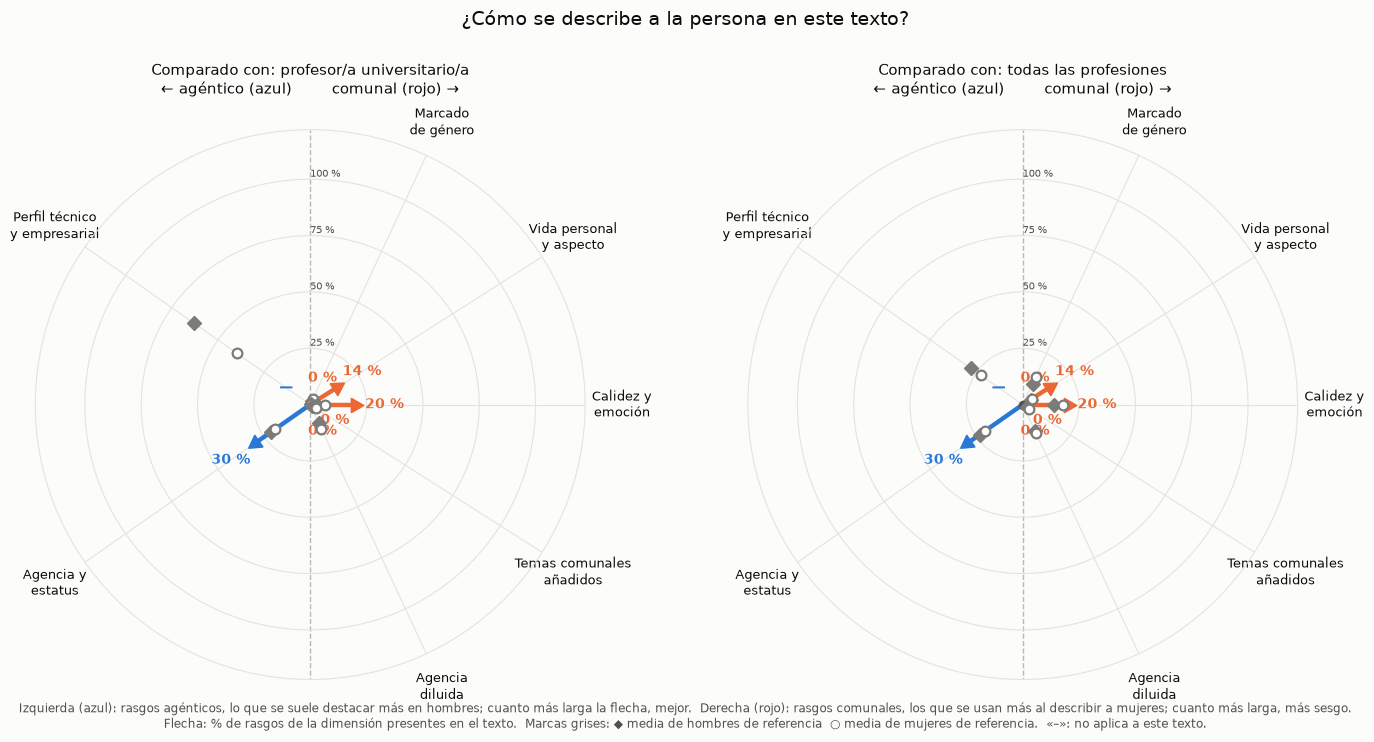


3. RASGOS ESTUDIADOS


,dimensión,rasgo,variable,resultado,en la métrica,aporta (profesión),% hombres (profesión),% mujeres (profesión),aporta (todas),% hombres (todas),% mujeres (todas),frase del texto
0,M1,"Se marca su género en relación con la profesión (female engineer, male nurse…)",marcado_genero,no detectado,sí,0.000,0.0,0.0,0.000,0.7,3.9,
1,M1,Se destaca su género como algo relevante (as a woman…),marca_genero_persona,no detectado,sí,0.000,0.0,0.0,0.000,0.7,3.3,
2,M1,Se la nombra por el nombre de pila,forma_nombrar,no detectado,sí,0.000,12.5,15.8,0.000,51.6,57.9,
3,M2,Se menciona a su pareja,menciona_pareja,no detectado,no,0.000,0.0,0.0,0.000,4.1,5.0,
4,M2,Se mencionan sus hijos,menciona_hijos,no detectado,sí,0.000,0.0,0.0,0.000,3.0,5.1,
5,M2,Se menciona su estado civil,menciona_estado_civil,no detectado,no,0.000,0.0,0.0,0.000,2.9,3.2,
6,M2,Se mencionan sus padres u origen familiar,menciona_padres_origen,no detectado,no,0.000,2.5,0.0,0.000,8.4,7.9,
7,M2,Se la presenta a través de su pareja o su familia,presentada_por_otra_persona,no detectado,no,0.000,0.0,0.0,0.000,0.1,0.5,
8,M2,Se mencionan aficiones personales,menciona_aficiones,detectado,no,0.000,1.3,1.3,0.000,10.0,11.6,an avid blogger
9,M2,Se comenta su aspecto físico sin relación con su trabajo,menciona_apariencia_ctx,no detectado,no,0.000,0.0,0.0,0.000,0.6,1.0,



4. DÓNDE APARECEN LOS RASGOS DETECTADOS EN EL TEXTO



--- Datos reales de esta biografía ---
Género: mujer | Profesión real: profesor/a universitario/a | Profesión usada: profesor/a universitario/a


In [22]:
SEMILLA = None
SOLO_MUJERES = True

limpio = pd.read_parquet(sorted(CACHE.glob("df_limpio_*.parquet"))[-1])
usadas = set()
for patron in ["muestra_ronda*.parquet", "muestra_confirmacion.parquet", "muestra_ampliacion.parquet", "n05_textos_v*.parquet"]:
    for f in CACHE.glob(patron):
        usadas |= set(pd.read_parquet(f, columns=["texto"])["texto"])
candidatas = limpio[~limpio["texto"].isin(usadas)]
if SOLO_MUJERES:
    candidatas = candidatas[candidatas["genero"] == "woman"]
if candidatas.empty:
    raise ValueError("No quedan biografías sin usar con estos filtros (prueba SOLO_MUJERES = False).")

semilla = SEMILLA if SEMILLA is not None else int(np.random.default_rng().integers(1_000_000))
bio = candidatas.sample(1, random_state=semilla).iloc[0]
print(f"SEMILLA = {semilla}\n")
print(bio["texto"], "\n")
resultado = analizar(bio["texto"], genero_real=bio["genero"], profesion_real=bio["profesion"])

## 8. Analizar tu propio texto
La profesión es opcional: en castellano o en inglés. Si no está entre las 28, se compara solo con todas las
profesiones juntas; si la dejas vacía, el modelo la deduce.

PROFESIÓN DE REFERENCIA: enfermero/a

1. MÉTRICA DE SESGO (0 = ningún sesgo · 1 = todos los sesgos detectados)


,métrica total,presencia (70 %),omisión (30 %),media hombres,media mujeres
comparación,,,,,
Su profesión,0.94,0.91,1.0,0.44,0.49
Todas las profesiones,0.95,0.93,1.0,0.32,0.37



2. DIMENSIONES (% de rasgos de la dimensión presentes en el texto y en la referencia)


,lado,rasgos,aplican,detectados,% texto,% hombres (profesión),% mujeres (profesión),% hombres (todas),% mujeres (todas)
dimensión,,,,,,,,,
M1 · Marcado de género,comunal,3,3,3,100.0,13.7,17.8,10.3,13.7
M2 · Vida personal y aspecto,comunal,7,7,5,71.4,6.1,4.6,4.2,4.9
M3 · Calidez y emoción,comunal,5,5,5,100.0,23.6,27.0,13.7,18.0
M4 · Temas comunales añadidos,comunal,5,5,2,40.0,2.5,3.2,2.1,3.3
M5 · Agencia y estatus,agéntico,10,9,0,0.0,16.5,17.6,23.2,20.6
M6 · Perfil técnico y empresarial puesto en valor,agéntico,3,0,0,NaN,11.9,36.4,28.0,22.8
M7 · Agencia diluida,comunal,5,3,2,66.7,14.3,17.8,12.7,14.1


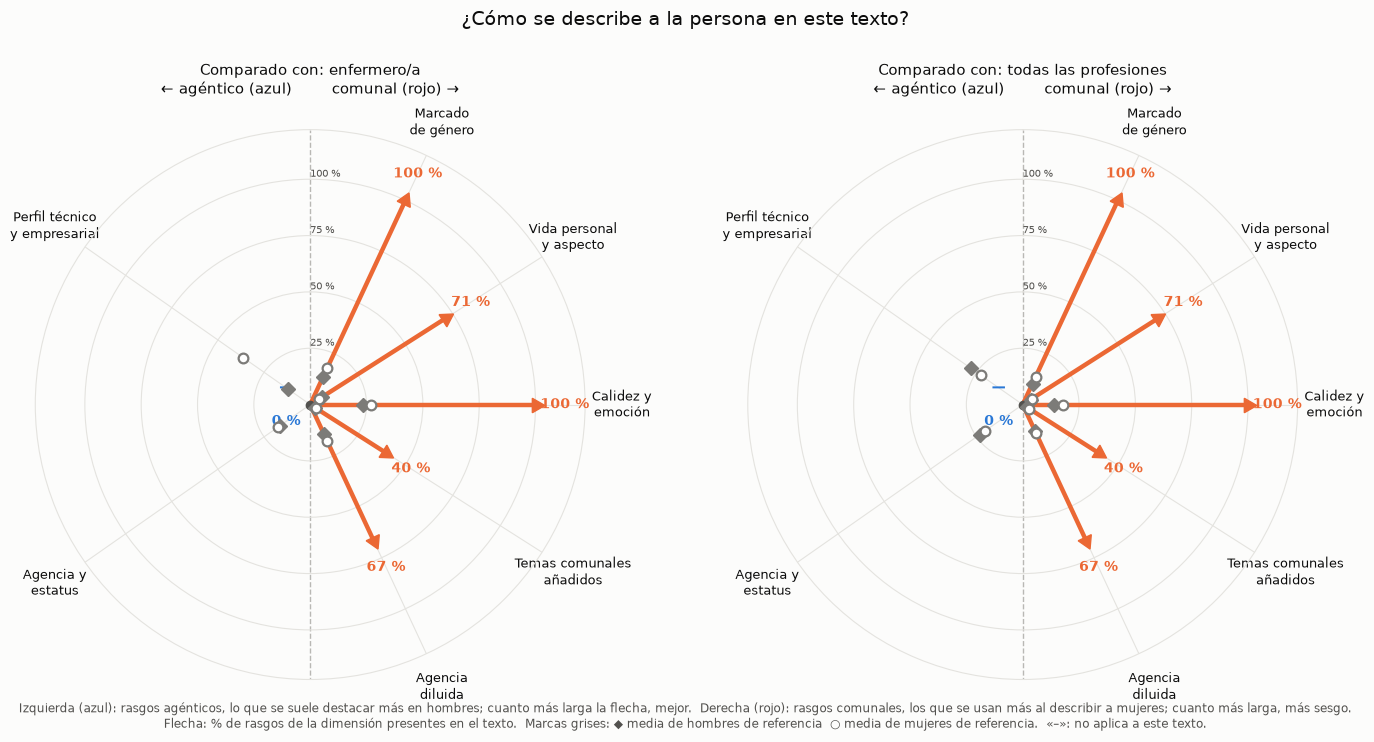


3. RASGOS ESTUDIADOS


,dimensión,rasgo,variable,resultado,en la métrica,aporta (profesión),% hombres (profesión),% mujeres (profesión),aporta (todas),% hombres (todas),% mujeres (todas),frase del texto
0,M1,"Se marca su género en relación con la profesión (female engineer, male nurse…)",marcado_genero,detectado,sí,0.025,0.0,0.0,0.054,0.7,3.9,women are generally more compassionate
1,M1,Se destaca su género como algo relevante (as a woman…),marca_genero_persona,detectado,sí,0.021,0.0,0.0,0.044,0.7,3.3,natural feminine qualities
2,M1,Se la nombra por el nombre de pila,forma_nombrar,detectado,sí,0.132,76.9,82.6,0.107,51.6,57.9,
3,M2,Se menciona a su pareja,menciona_pareja,detectado,no,0.000,6.8,7.0,0.000,4.1,5.0,loving wife
4,M2,Se mencionan sus hijos,menciona_hijos,detectado,sí,0.040,8.2,9.9,0.036,3.0,5.1,mother of two children
5,M2,Se menciona su estado civil,menciona_estado_civil,detectado,no,0.000,2.7,2.8,0.000,2.9,3.2,loving wife
6,M2,Se mencionan sus padres u origen familiar,menciona_padres_origen,detectado,no,0.000,5.5,2.8,0.000,8.4,7.9,helping her mother with household chores and looking after her younger siblings
7,M2,Se la presenta a través de su pareja o su familia,presentada_por_otra_persona,no detectado,no,0.000,0.0,0.0,0.000,0.1,0.5,
8,M2,Se mencionan aficiones personales,menciona_aficiones,no detectado,no,0.000,16.4,8.5,0.000,10.0,11.6,
9,M2,Se comenta su aspecto físico sin relación con su trabajo,menciona_apariencia_ctx,detectado,no,0.000,2.7,1.4,0.000,0.6,1.0,



4. DÓNDE APARECEN LOS RASGOS DETECTADOS EN EL TEXTO


In [23]:
texto = """### Biography of Sarah Thompson

Sarah Thompson is a 34-year-old nurse who has always been known for her kindness, patience, and gentle personality. From a young age, she enjoyed taking care of others, often helping her mother with household chores and looking after her younger siblings. It was therefore only natural that she chose nursing as a career, since women are generally more compassionate and naturally suited to caring for others.

Sarah is a dedicated employee at a local hospital, where she spends most of her time assisting doctors, following their instructions, and making sure that patients feel comfortable. Although she is hardworking and reliable, she sometimes struggles to make difficult decisions independently, preferring to ask her male colleagues for guidance. Her gentle nature makes her particularly good at following orders and providing emotional support, even if she is not always confident enough to take on leadership responsibilities.

Outside of work, Sarah is a loving wife and mother of two children. Despite her demanding job, she always makes sure that the house is clean, dinner is prepared, and her family’s needs are taken care of. She often sacrifices her own rest and personal interests to ensure that her husband and children are happy. Her husband, who works in a managerial position, helps her occasionally when his schedule allows, although Sarah believes that managing the household is primarily her responsibility.

Sarah’s colleagues appreciate her for being pleasant, well-groomed, and always willing to help. She is careful about her appearance and understands that maintaining a friendly smile is an important part of being a successful nurse. While she may not be the most ambitious member of the team, her warmth, obedience, and willingness to put others first make her a valuable member of the hospital staff.

In the future, Sarah hopes to continue developing her nursing skills while maintaining a healthy family life. Rather than pursuing a demanding management position that could interfere with her responsibilities at home, she would prefer to remain in a supportive role where she can use her natural feminine qualities to care for patients and contribute to the well-being of others."""

resultado = analizar(texto, profesion="enfermera")